# Вероятность: от кубика до уверенности модели

ФПМИ.Будущее · ИИ · Прекурс · Занятие 7

На занятии 5 дерево решений отвечало про пассажира «Титаника» коротко: выжил или нет. На самом деле внутри модель считает, **насколько вероятно**, что пассажир выжил, а «да/нет» получается из этого числа.

Сегодня разберёмся, что такое вероятность, как её считать по формуле и по данным, и как модель превращает вероятность в ответ. Без этого не понять метрики и классификацию.

## 0. Зачем

- **Модель классификации не уверена на 100%.** Она выдаёт вероятность: «этот пассажир выживет с вероятностью 0.63», «это письмо — спам с вероятностью 0.8». Чтобы пользоваться моделью, надо понимать, что значит это число.
- **На занятии 8 — метрики.** Все метрики классификации считаются из вероятностей модели и порога.
- **На занятии 9 — логистическая регрессия.** Она на выходе тоже даёт вероятность.
- **На олимпиаде** задачи на вероятность встречаются в математической части.

## 1. Вероятность и частота

Бросаем обычный кубик. Может выпасть 1, 2, 3, 4, 5 или 6, и все шесть вариантов одинаково возможны. Шестёрка — один вариант из шести, поэтому её вероятность $\frac{1}{6} \approx 0.167$.

Что это число значит на практике? Если бросать кубик много раз, шестёрка будет выпадать примерно в каждом шестом броске. Проверим: бросим кубик 10 000 раз с помощью numpy.

> **Определение**
>
> - **Случайный эксперимент** — действие, результат которого заранее не известен: бросили кубик, вытянули карту, подбросили монету. Дальше для краткости — просто эксперимент.
> - **Исход** — один из возможных результатов эксперимента: «выпала четвёрка».
> - **Событие** — то, что после эксперимента либо случилось, либо нет. Событие может состоять из нескольких исходов: «выпало чётное» — это исходы 2, 4, 6.
> - **Вероятность** события — число от 0 до 1, которое показывает, насколько событие ожидаемо: 0 — не бывает никогда, 1 — бывает всегда. Если все исходы одинаково возможны, вероятность события $P = \dfrac{\text{число подходящих исходов}}{\text{число всех исходов}}$. Например, $P(\text{чётное}) = \frac{3}{6} = \frac{1}{2}$.
> - **Частота** события — доля экспериментов, в которых оно случилось. Бросили 100 раз, шестёрка выпала 17 раз — частота $0.17$.

In [1]:
import numpy as np

rng = np.random.default_rng(0)
rolls = rng.integers(1, 7, size=10_000)   # 10 000 бросков: целые числа от 1 до 6
print("Первые 10 бросков:", rolls[:10])
print("Частота шестёрки в первых 10:", (rolls[:10] == 6).mean())
print("Частота шестёрки в 10 000:", (rolls == 6).mean().round(3))

Первые 10 бросков: [6 4 4 2 2 1 1 1 2 5]
Частота шестёрки в первых 10: 0.1
Частота шестёрки в 10 000: 0.169


`(rolls == 6).mean()` — приём из занятия 1: среднее булевой маски равно доле `True`, то есть частоте события.

Посмотрим, как частота меняется по мере бросков.

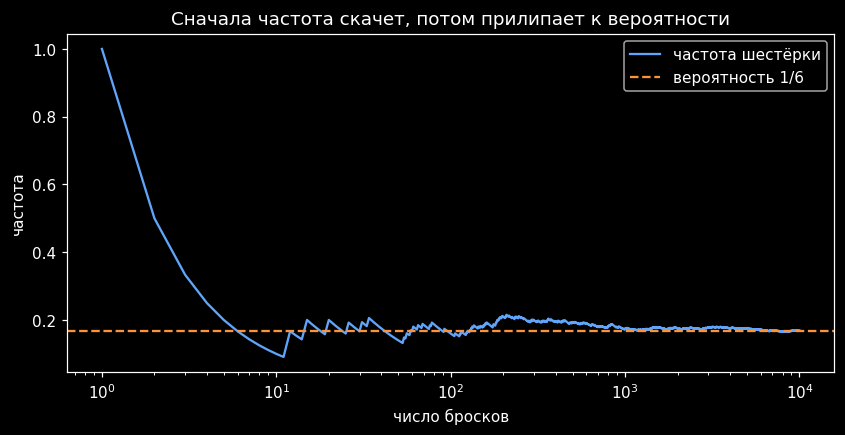

In [2]:
import matplotlib.pyplot as plt
plt.style.use("dark_background")

n = np.arange(1, len(rolls) + 1)
freq = (rolls == 6).cumsum() / n          # частота шестёрки после первых n бросков
plt.figure(figsize=(9, 4))
plt.plot(n, freq, color="#60a5fa", label="частота шестёрки")
plt.axhline(1 / 6, color="#fb923c", ls="--", label="вероятность 1/6")
plt.xscale("log"); plt.xlabel("число бросков"); plt.ylabel("частота"); plt.legend()
plt.title("Сначала частота скачет, потом прилипает к вероятности")
plt.show()

**Вывод.** На малом числе экспериментов частота может быть какой угодно. Чем больше экспериментов, тем ближе частота к вероятности. Поэтому вероятность можно **оценить по данным**: посчитать долю случаев, в которых событие произошло.

**Проверь себя.** Монету бросили 10 раз, орёл выпал 7 раз. Значит, вероятность орла у этой монеты 0.7?

<details>
<summary>Показать ответ</summary>

Нет. 0.7 — это частота на 10 бросках, а по картинке видно, как сильно частота скачет на малом числе экспериментов. У честной монеты 7 орлов из 10 выпадают примерно в 12% серий. Чтобы оценить вероятность надёжно, нужно много бросков.

</details>

**Вопрос в чат.** Бросаем две кости. Что вероятнее: сумма 11 или сумма 12? Или одинаково?

<details>
<summary>Показать ответ</summary>

Сумма 11 вдвое вероятнее: $\frac{2}{36}$ против $\frac{1}{36}$. Почему — в задаче 1.

</details>

### Задача 1. Две кости

Бросаем две честные кости — красную и синюю.

1. Какова вероятность, что сумма очков равна 8?
2. Какая сумма выпадает чаще всего? Какая реже всего?
3. Лейбниц рассуждал так: сумма 11 получается одним способом (5 и 6), сумма 12 — тоже одним (6 и 6). Значит, они одинаково вероятны. Где ошибка?

**★ Посложнее.** Три кости. Сумма 9 раскладывается на слагаемые шестью способами (1+2+6, 1+3+5, 1+4+4, 2+2+5, 2+3+4, 3+3+3), сумма 10 — тоже шестью. Одинаково ли они вероятны?

<details>
<summary>Показать решение</summary>

Всего исходов $6 \cdot 6 = 36$, все одинаково возможны. Удобно нарисовать таблицу 6×6: строка — красная кость, столбец — синяя, в клетке сумма.

1. Сумма 8: (2, 6), (3, 5), (4, 4), (5, 3), (6, 2) — 5 клеток. $P = \frac{5}{36}$.
2. Чаще всего — 7: вся диагональ, 6 клеток, $P = \frac{6}{36} = \frac{1}{6}$. Реже всего — 2 и 12: по одной клетке, $\frac{1}{36}$.
3. Одинаково возможны не наборы чисел, а исходы «что на красной, что на синей». Сумма 11 — это две клетки: (5, 6) и (6, 5). Сумма 12 — одна: (6, 6). Поэтому $\frac{2}{36}$ против $\frac{1}{36}$.

★ Нет: у суммы 9 — 25 исходов из 216, у суммы 10 — 27. Разбиение 3+3+3 даёт один исход, а 1+2+6 — шесть (порядок костей разный). Этот вопрос задавали Галилею игроки в кости.

**Вывод:** считать нужно равновозможные исходы. Кости честные, а суммы не равновероятны.

</details>

#### Проверка

Та же таблица 6×6 в numpy: строка — красная кость, столбец — синяя (приём с `[:, None]` из занятия 1).

In [3]:
a = np.arange(1, 7)
sums = a[:, None] + a            # таблица 6×6: в клетке сумма очков
print(sums)
print("Исходов с суммой 8:", (sums == 8).sum(), "из 36")
print("Сумма 11:", (sums == 11).sum(), "исхода, сумма 12:", (sums == 12).sum())

[[ 2  3  4  5  6  7]
 [ 3  4  5  6  7  8]
 [ 4  5  6  7  8  9]
 [ 5  6  7  8  9 10]
 [ 6  7  8  9 10 11]
 [ 7  8  9 10 11 12]]
Исходов с суммой 8: 5 из 36
Сумма 11: 2 исхода, сумма 12: 1


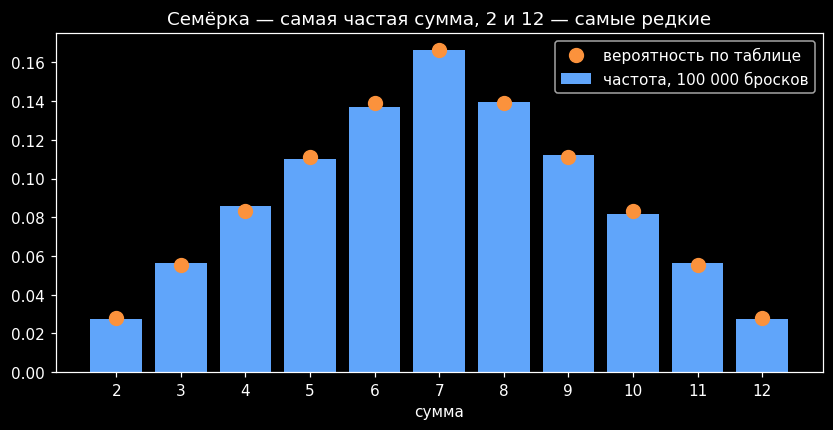

In [4]:
rng = np.random.default_rng(1)
two = rng.integers(1, 7, size=(100_000, 2)).sum(axis=1)     # 100 000 бросков двух костей
values = np.arange(2, 13)
plt.figure(figsize=(9, 4))
plt.bar(values, [(two == s).mean() for s in values], color="#60a5fa", label="частота, 100 000 бросков")
plt.plot(values, [(sums == s).sum() / 36 for s in values], "o", color="#fb923c", ms=9, label="вероятность по таблице")
plt.xticks(values); plt.xlabel("сумма"); plt.legend(); plt.title("Семёрка — самая частая сумма, 2 и 12 — самые редкие")
plt.show()

In [5]:
s3 = a[:, None, None] + a[:, None] + a       # три кости: 216 исходов
print("Сумма 9:", (s3 == 9).sum(), "из 216")
print("Сумма 10:", (s3 == 10).sum(), "из 216")

Сумма 9: 25 из 216
Сумма 10: 27 из 216


**Для ML.** Вероятность можно посчитать по формуле, если знаешь, как устроен эксперимент (кубик). А можно оценить частотой по данным, если не знаешь (пассажиры «Титаника»). Модели машинного обучения обычно делают второе.

## 2. Условная вероятность

Возвращаемся к «Титанику» из занятия 5. Какова вероятность, что случайно выбранный пассажир выжил? А если мы знаем, что у него билет первого класса?

In [6]:
import os
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
local = "data/titanic.csv"   # копия в папке занятия — если интернета нет
titanic = pd.read_csv(local if os.path.exists(local) else url)
print("Пассажиров:", len(titanic), "| выжили:", titanic["survived"].sum())
pd.crosstab(titanic["pclass"], titanic["survived"], margins=True, margins_name="всего")

Пассажиров: 891 | выжили: 342


survived,0,1,всего
pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
всего,549,342,891


Строки — класс билета, столбцы — погиб (0) или выжил (1), последняя строка и столбец — итоги.

Когда мы узнали про пассажира что-то ещё (например, класс), вероятность может измениться. Мы как бы убираем из таблицы всех, кто не подходит под условие, и считаем долю только среди оставшихся.

> **Определение**
>
> **Условная вероятность** — вероятность события A, когда уже известно, что случилось событие B. Пишут $P(A \mid B)$, читают «вероятность A при условии B».
>
> Как считать по таблице: оставляем только те случаи, где случилось B, и находим среди них долю случаев с A:
>
> $$P(A \mid B) = \frac{\text{сколько случаев, где случились и A, и B}}{\text{сколько случаев, где случилось B}}.$$
>
> Главное — **знаменатель**: делим не на всех, а только на тех, кто подходит под условие.

**Вопрос в чат.** Среди выживших пассажиров больше половины — из первого класса? Да или нет?

<details>
<summary>Показать ответ</summary>

Нет, 136 из 342 — меньше 40%. Хотя в первом классе выжило почти две трети. Разбираем в задаче 2.

</details>

### Задача 2. Кто выжил

По таблице выше:

1. Какова вероятность, что случайный пассажир выжил?
2. Какова вероятность выжить, если у пассажира билет первого класса: $P(\text{выжил} \mid 1\text{ класс})$?
3. А наоборот: какая доля выживших ехала первым классом, $P(1\text{ класс} \mid \text{выжил})$? Это то же самое число?
4. В третьем классе шансы выжить маленькие. Почему же выживших из третьего класса почти столько же, сколько из первого?

**★ Посложнее.** Получите ответ пункта 3 из ответа пункта 2, не глядя на столбец «выжил»: известно только $P(\text{выжил} \mid 1\text{ класс})$, доля первого класса среди всех пассажиров и $P(\text{выжил})$.

<details>
<summary>Показать решение</summary>

1. $P(\text{выжил}) = \frac{342}{891} \approx 0.38$.
2. Оставляем строку «1 класс»: $P(\text{выжил} \mid 1) = \frac{136}{216} \approx 0.63$. Узнали класс — и вероятность выросла с 0.38 до 0.63.
3. Оставляем столбец «выжил»: $P(1 \mid \text{выжил}) = \frac{136}{342} \approx 0.40$. Числитель тот же, 136, а знаменатель другой. **$P(A \mid B)$ и $P(B \mid A)$ — разные числа.** В первом классе выжили почти две трети, а среди выживших первоклассники — меньше половины.
4. $P(\text{выжил} \mid 3) = \frac{119}{491} \approx 0.24$ — мало. Но третий класс большой: 491 человек против 216. Маленькая доля от большой группы дала 119 выживших — почти как 136 в первом.

★ $P(1 \mid \text{выжил}) = \dfrac{P(\text{выжил} \mid 1) \cdot P(1)}{P(\text{выжил})} = \dfrac{0.630 \cdot \frac{216}{891}}{0.384} \approx 0.40$. Это **формула Байеса**: она переворачивает условную вероятность.

**Вывод:** условная вероятность зависит от того, кто стоит после черты. Перепутать условие и событие — частая ошибка в задачах на вероятность.

</details>

#### Проверка

Условная вероятность по данным — это `groupby` из занятия 3: среднее столбца 0/1 внутри группы и есть доля выживших в группе.

In [7]:
print("P(выжил):", titanic["survived"].mean().round(3))
print("P(выжил | класс):")
print(titanic.groupby("pclass")["survived"].mean().round(3))

P(выжил): 0.384
P(выжил | класс):
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


In [8]:
survivors = titanic[titanic["survived"] == 1]            # оставили только выживших
print("P(класс | выжил):")
print(survivors["pclass"].value_counts(normalize=True).sort_index().round(3))

P(класс | выжил):
pclass
1    0.398
2    0.254
3    0.348
Name: proportion, dtype: float64


Пола среди признаков модели на занятии 5 не было. А он меняет вероятность выжить сильнее, чем класс.

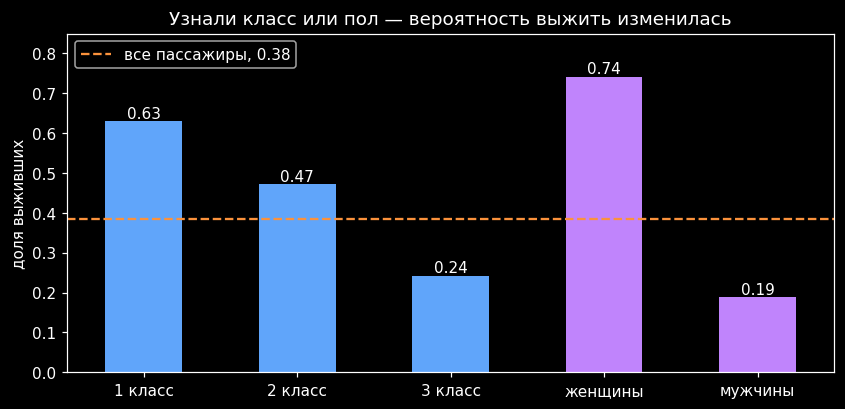

In [9]:
by_class = titanic.groupby("pclass")["survived"].mean()
by_sex = titanic.groupby("sex")["survived"].mean().rename({"female": "женщины", "male": "мужчины"})
groups = pd.concat([by_class.rename(lambda c: f"{c} класс"), by_sex])
ax = groups.plot.bar(rot=0, figsize=(9, 4), ylim=(0, 0.85), color=["#60a5fa"] * 3 + ["#c084fc"] * 2)
line = ax.axhline(titanic["survived"].mean(), color="#fb923c", ls="--", label="все пассажиры, 0.38")
ax.bar_label(ax.containers[0], fmt="%.2f"); ax.legend(handles=[line])
ax.set_ylabel("доля выживших"); ax.set_title("Узнали класс или пол — вероятность выжить изменилась")
plt.show()

**Проверь себя.** Среди женщин выжили 74%. Значит, среди выживших 74% — женщины?

<details>
<summary>Показать ответ</summary>

Нет, это перевёрнутая условная вероятность. $P(\text{выжил} \mid \text{женщина}) = \frac{233}{314} \approx 0.74$, а $P(\text{женщина} \mid \text{выжил}) = \frac{233}{342} \approx 0.68$. Числитель тот же, знаменатели разные.

</details>

**Для ML.** Модель классификации оценивает именно условную вероятность: $P(\text{выжил} \mid \text{признаки пассажира})$. То есть насколько вероятен ответ, если признаки известны.

## 3. Независимость

Бросаем две кости. Красная кость «не знает», что выпало на синей, и наоборот. Такие события называют независимыми.

> **Определение**
>
> - События A и B **независимы**, если одно не влияет на шансы другого: узнали, что случилось B, — а вероятность A не изменилась, $P(A \mid B) = P(A)$.
> - Для независимых событий вероятность того, что случатся **оба**, равна произведению: $P(A \text{ и } B) = P(A) \cdot P(B)$.
> - **Противоположное событие** «A не случилось» имеет вероятность $1 - P(A)$. Особенно удобно для вопросов «хотя бы один раз»: «хотя бы один раз» — это противоположность «ни разу».

**Вопрос в чат.** Бросаем кость 6 раз. Вероятность, что хотя бы раз выпадет шестёрка: равна 1, больше 1/2 или меньше 1/2?

<details>
<summary>Показать ответ</summary>

Больше 1/2, но не 1: $1 - \left(\frac{5}{6}\right)^6 \approx 0.665$. Бывает, что шесть бросков подряд без шестёрки. Разбираем в задаче 3.

</details>

### Задача 3. Хотя бы одна шестёрка

1. Бросаем две кости. Какова вероятность, что на обеих шестёрки?
2. Какова вероятность, что хотя бы на одной кости шестёрка? Почему не $\frac{1}{6} + \frac{1}{6} = \frac{1}{3}$?
3. Бросаем одну кость 6 раз. Какова вероятность хотя бы одной шестёрки? Правда ли, что $6 \cdot \frac{1}{6} = 1$, то есть шестёрка выпадет наверняка?

**★ Посложнее.** Что вероятнее: хотя бы одна шестёрка за 4 броска одной кости или хотя бы одна пара шестёрок за 24 броска двух костей? (Задача шевалье де Мере, 1654 год.)

<details>
<summary>Показать решение</summary>

1. Броски независимы: $\frac{1}{6} \cdot \frac{1}{6} = \frac{1}{36}$. В таблице 6×6 это одна клетка (6, 6).
2. Клеток с шестёркой: строка 6 и столбец 6, это $6 + 6 - 1 = 11$, потому что клетка (6, 6) общая. $P = \frac{11}{36}$. Сумма $\frac{1}{6} + \frac{1}{6}$ считает (6, 6) дважды.
   Через противоположное событие: «хотя бы одна шестёрка» — противоположность «ни одной шестёрки». $P(\text{ни одной}) = \frac{5}{6} \cdot \frac{5}{6} = \frac{25}{36}$, значит, $P = 1 - \frac{25}{36} = \frac{11}{36}$.
3. $P(\text{ни одной за 6 бросков}) = \left(\frac{5}{6}\right)^6 \approx 0.335$, $P(\text{хотя бы одна}) \approx 0.665$. Не 1! А при 7 бросках $7 \cdot \frac{1}{6} > 1$ — вероятность больше единицы не бывает. **Складывать вероятности «хотя бы одного» нельзя, считаем через «ни разу».**

★ $1 - \left(\frac{5}{6}\right)^4 \approx 0.518$ против $1 - \left(\frac{35}{36}\right)^{24} \approx 0.491$. Первое вероятнее, хотя «на глаз» оба варианта одинаковые.

</details>

#### Проверка

In [10]:
has_six = (a[:, None] == 6) | (a == 6)      # таблица 6×6: есть ли хоть одна шестёрка
print("Хотя бы одна шестёрка на двух костях:", has_six.sum(), "исходов из 36")
rng = np.random.default_rng(2)
six_rolls = rng.integers(1, 7, size=(100_000, 6))           # 100 000 серий по 6 бросков
print("6 бросков, частота «хотя бы одна шестёрка»:", (six_rolls == 6).any(axis=1).mean().round(3))
print("По формуле 1 − (5/6)^6:", round(1 - (5 / 6) ** 6, 3))

Хотя бы одна шестёрка на двух костях: 11 исходов из 36
6 бросков, частота «хотя бы одна шестёрка»: 0.667
По формуле 1 − (5/6)^6: 0.665


**Независимость в данных.** Класс билета и выживание **зависимы**: $P(\text{выжил} \mid 1\text{ класс}) = 0.63$, а $P(\text{выжил}) = 0.38$. Знание класса меняет вероятность, поэтому класс — полезный признак.

А как выглядит независимый признак? Добавим пассажирам столбец «монетка»: для каждого подбросим монету, 0 или 1.

In [11]:
coin_rng = np.random.default_rng(7)
titanic["монетка"] = coin_rng.integers(0, 2, size=len(titanic))   # случайный 0/1, с судьбой не связан
print("P(выжил):", titanic["survived"].mean().round(3))
print(titanic.groupby("монетка")["survived"].mean().round(3))

P(выжил): 0.384
монетка
0    0.371
1    0.396
Name: survived, dtype: float64


При любом значении монетки доля выживших почти та же, что у всех пассажиров. Монетка ничего не говорит о судьбе пассажира.

**Для ML.** Признак полезен, если таргет от него **зависит**. Если признак и таргет независимы, модели от такого признака нет пользы.

**Проверь себя.** Монету подбросили 5 раз, и 5 раз выпала решка. Теперь орёл вероятнее?

<details>
<summary>Показать ответ</summary>

Нет, по-прежнему $\frac{1}{2}$. Броски независимы: монета не помнит прошлого. Ошибку «теперь-то уж точно орёл» называют ошибкой игрока.

А вот вероятность серии «5 решек подряд» до начала бросков была маленькой: $\left(\frac{1}{2}\right)^5 = \frac{1}{32}$. Это разные вопросы.

</details>

**Проверь себя.** ★ Почему у монетки получилось 0.371 и 0.396, а не ровно 0.384?

<details>
<summary>Показать ответ</summary>

Это частоты на конечной выборке, около 450 пассажиров в каждой группе. Они колеблются вокруг вероятности, как частота шестёрки на первом графике. С другим `default_rng(...)` числа будут другими, но тоже близкими к 0.384.

</details>

## 4. Случайная величина и матожидание

Часто результат эксперимента — это число: сколько очков выпало, сколько рублей выиграли в лотерею, сколько пассажиров выжило. Такое число называют случайной величиной.

> **Определение**
>
> **Случайная величина** — число, которое мы узнаём только после эксперимента.
>
> Строже: это правило, которое **каждому исходу** эксперимента ставит в соответствие число. То есть функция $X$, заданная на множестве всех исходов (его обозначают $\Omega$, «омега»).
>
> Пример: бросаем две кости. Исходов 36 — пары $(a, b)$. Сумма очков $X(a, b) = a + b$ — случайная величина: каждой паре она сопоставляет число. Таблица 6×6 из задачи 1 — это и есть функция $X$, выписанная целиком.

> **Определение**
>
> **Распределение** случайной величины — список её значений и их вероятностей. Вероятность $P(X = x)$ равна сумме вероятностей тех исходов, на которых $X$ принимает значение $x$.
>
> Например, $P(X = 8) = \frac{5}{36}$: в таблице пять клеток с числом 8.

> **Определение**
>
> **Математическое ожидание** (матожидание, среднее значение) — сколько в среднем получится, если повторять эксперимент очень много раз. Считают так: каждое значение умножают на его вероятность и всё складывают:
>
> $$E X = x_1 p_1 + x_2 p_2 + \ldots + x_k p_k.$$
>
> Для одного кубика: $E X = 1 \cdot \frac{1}{6} + 2 \cdot \frac{1}{6} + \ldots + 6 \cdot \frac{1}{6} = \frac{21}{6} = 3.5$.

| очки $x$ | 1 | 2 | 3 | 4 | 5 | 6 |
| --- | --- | --- | --- | --- | --- | --- |
| вероятность $p$ | 1/6 | 1/6 | 1/6 | 1/6 | 1/6 | 1/6 |

Распределение суммы двух костей получим прямо из таблицы `sums` из задачи 1: для каждого значения считаем, в скольких клетках оно стоит.

In [12]:
values, counts = np.unique(sums, return_counts=True)   # значения X и число исходов для каждого
print("Значения X:     ", values)
print("Исходов из 36:  ", counts)
print("E X =", (values * counts / 36).sum().round(3))

Значения X:      [ 2  3  4  5  6  7  8  9 10 11 12]
Исходов из 36:   [1 2 3 4 5 6 5 4 3 2 1]
E X = 7.0


In [13]:
print("Среднее очков за 10 000 бросков:", rolls.mean().round(3))
print("Матожидание по формуле:", (np.arange(1, 7) * (1 / 6)).sum().round(3))

Среднее очков за 10 000 бросков: 3.504
Матожидание по формуле: 3.5


**Проверь себя.** Матожидание очков на кубике 3.5. Может ли на кубике выпасть 3.5? Значит ли матожидание, что это «самый вероятный» результат?

<details>
<summary>Показать ответ</summary>

Выпасть 3.5 не может. И самым вероятным значением оно не является: у кубика все значения одинаково вероятны. Матожидание — это **среднее на длинной дистанции**, а не прогноз одного броска.

</details>

### Задача 4. Лотерея

Билет стоит 50 ₽. С вероятностью $\frac{1}{10}$ билет выигрывает 300 ₽, иначе — ничего.

1. Какие значения принимает чистый выигрыш (выигрыш минус цена билета) и с какими вероятностями? Найдите его матожидание.
2. Каким должен быть приз, чтобы матожидание стало 0 (честная игра)? А если приз оставить 300 ₽, какой должна быть цена билета?

**★ Посложнее.** Если купить 1000 таких билетов, сколько в среднем получится выигрышных и каким в среднем будет итог?

<details>
<summary>Показать решение</summary>

1. Чистый выигрыш: $300 - 50 = 250$ с вероятностью $0.1$ и $-50$ с вероятностью $0.9$.
   $E = 250 \cdot 0.1 + (-50) \cdot 0.9 = 25 - 45 = -20$. Короче: $300 \cdot 0.1 - 50 = -20$. В среднем каждый билет приносит минус 20 ₽.
2. Приз $x$: $0.1 x - 50 = 0 \Rightarrow x = 500$. Цена $c$ при призе 300: $30 - c = 0 \Rightarrow c = 30$.

★ Выигрышных в среднем $1000 \cdot 0.1 = 100$, итог в среднем $1000 \cdot (-20) = -20\,000$ ₽. Матожидание суммы равно сумме матожиданий.

**Вывод:** иногда выигрываешь, но в среднем на дистанции проигрываешь 20 ₽ с билета. Так устроены лотереи: матожидание выигрыша у игрока отрицательное.

</details>

#### Проверка

Матожидание — это сумма «значение × вероятность», то есть скалярное произведение вектора значений на вектор вероятностей из занятия 2.

In [14]:
values = np.array([250, -50])      # чистый выигрыш: билет выиграл / не выиграл
probs = np.array([0.1, 0.9])
print("Матожидание:", values @ probs)
rng = np.random.default_rng(3)
tickets = rng.choice(values, size=100_000, p=probs)          # купили 100 000 билетов
print("Средний выигрыш за 100 000 билетов:", tickets.mean().round(2))

Матожидание: -20.0
Средний выигрыш за 100 000 билетов: -19.37


**Проверь себя.** Матожидание выигрыша −20 ₽. Значит, каждый, кто купил билет, потерял 20 ₽?

<details>
<summary>Показать ответ</summary>

Нет. Каждый покупатель получил либо +250, либо −50, ровно −20 не получил никто. −20 — это средний результат по многим билетам.

</details>

**Для ML.** Функция потерь MSE из занятия 6 — это средняя ошибка по объектам train, то есть оценка матожидания ошибки модели. Уменьшая ошибку на train, мы надеемся уменьшить её и на новых объектах — это и проверяет test.

## 5. Модель выдаёт вероятность, ответ получается по порогу

Таблица из раздела 2 — это уже модель. Приходит новый пассажир первого класса, и мы говорим: «вероятность выжить 0.63». Чтобы ответить «выжил» или «погиб», нужен **порог**: если вероятность не меньше порога, отвечаем «выжил».

In [15]:
p_class = titanic.groupby("pclass")["survived"].mean()        # «модель»: P(выжил | класс)
proba_class = titanic["pclass"].map(p_class)                   # вероятность для каждого пассажира
pred = (proba_class >= 0.5).astype(int)                         # порог 0.5
print("Говорим «выжил» классам:", list(p_class[p_class >= 0.5].index))
print("Доля ошибок:", (pred != titanic["survived"]).mean().round(3))

Говорим «выжил» классам: [1]
Доля ошибок: 0.321


Это ровно правило «выжил, если класс ≤ 1» из занятия 5, у которого перебором получилась наименьшая доля ошибок 0.321. Теперь видно, почему t = 1 лучший: только у первого класса вероятность выжить больше половины.

Теперь дерево глубины 3 из занятия 5: те же признаки, то же разбиение на train и test.

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

features = ["pclass", "age", "sibsp", "parch", "fare"]
X = titanic[features].copy()
X["age"] = X["age"].fillna(X["age"].median())
y = titanic["survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
tree = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
proba = tree.predict_proba(X_test)[:, 1]      # вероятность класса 1 — «выжил»
X_test.head().assign(вероятность=proba[:5].round(3), выжил_на_деле=y_test[:5].values)

,pclass,age,sibsp,parch,fare,вероятность,выжил_на_деле
709,3,28.0,1,1,15.2458,0.249,1
439,2,31.0,0,0,10.5000,0.408,0
840,3,20.0,0,0,7.9250,0.249,0
720,2,6.0,0,1,33.0000,1.000,1
39,3,14.0,1,0,11.2417,0.249,1


`predict_proba` возвращает для каждого объекта два числа: вероятность класса 0 и вероятность класса 1 (в сумме 1). Берём второй столбец `[:, 1]`.

**Откуда дерево берёт вероятность?** Дерево делит пассажиров train на группы — листья. Новый пассажир попадает в один лист, и вероятность — это доля выживших среди пассажиров train в этом листе.

In [18]:
leaf = tree.apply(X_test.iloc[[0]])[0]              # в какой лист попал первый пассажир test
in_leaf = tree.apply(X_train) == leaf               # пассажиры train в том же листе
print("Пассажиров train в этом листе:", in_leaf.sum())
print("Из них выжили:", y_train[in_leaf].sum(), "→ доля", y_train[in_leaf].mean().round(3))

Пассажиров train в этом листе: 305
Из них выжили: 76 → доля 0.249


Этот лист — «3 класс, возраст от 6.5 до 32.5 лет». Вероятность 0.249 — это $P(\text{выжил} \mid \text{попал в этот лист})$, **условная вероятность**, посчитанная по train.

А знакомый `predict` — это та же вероятность и порог 0.5:

In [19]:
print("predict совпадает с «вероятность ≥ 0.5»:", (tree.predict(X_test) == (proba >= 0.5)).all())

predict совпадает с «вероятность ≥ 0.5»: True


**Порог не обязан быть 0.5.** Посмотрим, что будет, если его двигать.

**Вопрос в чат.** Поднимем порог с 0.5 до 0.8. Выжившими модель назовёт больше пассажиров или меньше?

<details>
<summary>Показать ответ</summary>

Меньше: чтобы получить ответ «выжил», теперь нужна вероятность от 0.8. Из 179 пассажиров test таких 6, а при пороге 0.5 было 33.

</details>

In [20]:
rows = []
for t in [0.2, 0.5, 0.8]:
    said = proba >= t                                 # кому модель говорит «выжил»
    rows.append([t, said.sum(), (said & (y_test == 0)).sum(), (~said & (y_test == 1)).sum()])
pd.DataFrame(rows, columns=["порог", "сказали «выжил»", "сказали «выжил», а погиб",
                            "сказали «погиб», а выжил"]).set_index("порог")

,сказали «выжил»,"сказали «выжил», а погиб","сказали «погиб», а выжил"
порог,,,
0.2,162,90,2
0.5,33,6,47
0.8,6,0,68


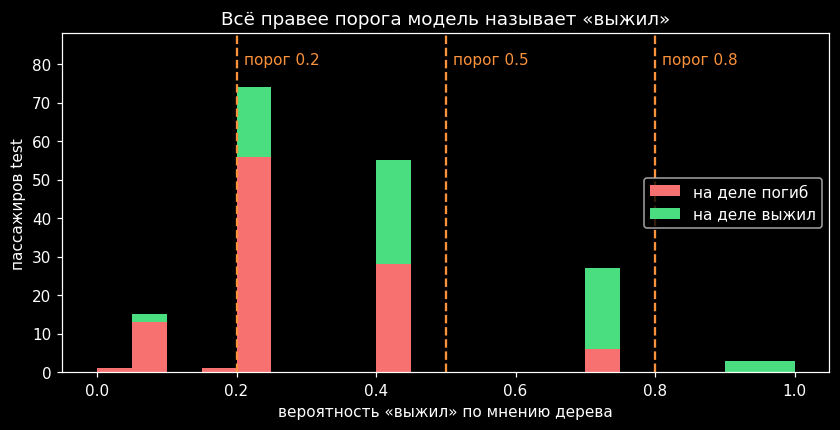

In [21]:
plt.figure(figsize=(9, 4))
bins = np.linspace(0, 1, 21)
plt.hist([proba[y_test == 0], proba[y_test == 1]], bins=bins, stacked=True,
         color=["#f87171", "#4ade80"], label=["на деле погиб", "на деле выжил"])
for t in [0.2, 0.5, 0.8]:
    plt.axvline(t, color="#fb923c", ls="--"); plt.text(t + 0.01, 80, f"порог {t}", color="#fb923c")
plt.ylim(0, 88); plt.xlabel("вероятность «выжил» по мнению дерева"); plt.ylabel("пассажиров test")
plt.legend(loc="center right")
plt.title("Всё правее порога модель называет «выжил»"); plt.show()

**Вывод.** Сдвигаем порог — меняется, какие ошибки делает модель. Низкий порог: почти никого из выживших не пропускаем, но многим погибшим говорим «выжил». Высокий порог — наоборот. **Одна ошибка уменьшается, другая растёт.** Какой порог лучше и как это измерить — на занятии 8.

**Проверь себя.** ★ У одного листа дерева вероятность «выжил» равна 1.0: в нём 16 пассажиров train, и все выжили. Верить, что новый пассажир из этого листа выживет наверняка?

<details>
<summary>Показать ответ</summary>

Осторожно. 16 пассажиров — маленькая группа. Как с монетой из раздела 1: частота на малом числе экспериментов может сильно отличаться от вероятности. «1.0» значит «в train все такие выжили», а не «выживет наверняка».

</details>

**Проверь себя.** ★ Сложим вероятности `proba` по всем 179 пассажирам test. Что означает эта сумма?

<details>
<summary>Показать ответ</summary>

Это матожидание числа выживших в test по мнению модели (у величины «выжил: 1 или 0» матожидание равно вероятности, а матожидания складываются). Получается 68.2, на деле выжили 74 — модель немного недооценивает шансы.

</details>

In [22]:
print("Сумма вероятностей по test:", proba.sum().round(1), "| выжили на деле:", y_test.sum())

Сумма вероятностей по test: 68.2 | выжили на деле: 74


## 6. Спам и цена ошибки

Порог 0.5 выглядит естественным: «вероятнее да, чем нет». Но всегда ли он правильный?

**Вопрос в чат.** Фильтр почты уверен, что письмо — спам, с вероятностью 0.8. Куда его класть: в «Спам» или во «Входящие»?

<details>
<summary>Показать ответ</summary>

Зависит от того, какая ошибка дороже. При условиях задачи 5 выгоднее оставить во «Входящих», хотя модель на 80% уверена, что это спам.

</details>

### Задача 5. Спам

Фильтр почты оценил: письмо — спам с вероятностью $p = 0.8$.

- Если убрать в «Спам» нормальное письмо, мы пропустим что-то важное. Потеря — **10** (условных единиц).
- Если оставить спам во «Входящих», мы потратим секунду, чтобы его удалить. Потеря — **1**.

1. Найдите ожидаемую потерю (матожидание потери) для каждого действия: «в Спам» и «во Входящие». Что выгоднее?
2. При какой вероятности спама $p$ оба действия одинаково выгодны? Это и есть порог: выше него убираем в «Спам».
3. А что если обе ошибки стоят одинаково, по 1? Какой будет порог?
4. А что если это не почта, а медицина: модель оценивает вероятность болезни. Пропустить больного — потеря 100, отправить здорового на лишнее обследование — потеря 1. При какой вероятности болезни стоит отправлять на обследование?

**★ Посложнее.** Выведите общую формулу порога, если ложная тревога стоит $a$, а пропуск стоит $b$.

<details>
<summary>Показать решение</summary>

1. «В Спам»: ошибаемся, если письмо нормальное, это вероятность $1 - p = 0.2$. Ожидаемая потеря $0.2 \cdot 10 = 2$.
   «Во Входящие»: ошибаемся, если письмо спам, это вероятность $0.8$. Ожидаемая потеря $0.8 \cdot 1 = 0.8$.
   $0.8 < 2$ — **оставляем во «Входящих», хотя модель на 80% уверена, что это спам.**
2. $p \cdot 1 = (1 - p) \cdot 10 \Rightarrow 11p = 10 \Rightarrow p = \frac{10}{11} \approx 0.91$. Убираем в «Спам», только если модель уверена больше чем на 91%.
3. $p = 1 - p \Rightarrow p = 0.5$. **Порог 0.5 правильный, только когда обе ошибки стоят одинаково.**
4. Отправляем, если $p \cdot 100 > (1 - p) \cdot 1$, то есть $p > \frac{1}{101} \approx 0.01$. На обследование — уже при 1% риска.

★ Сравниваем $p \cdot b$ и $(1 - p) \cdot a$: порог $p^* = \dfrac{a}{a + b}$. Чем дороже пропуск $b$, тем ниже порог.

**Вывод:** модель говорит, насколько вероятно. Что делать — решает порог, а порог выбирают по цене ошибок.

</details>

#### Проверка

In [23]:
p = 0.8
print("В «Спам»: ожидаемая потеря", round((1 - p) * 10, 2))
print("Во «Входящие»: ожидаемая потеря", round(p * 1, 2))
print("Порог 10/11:", round(10 / 11, 3), "| медицина 1/101:", round(1 / 101, 3))

В «Спам»: ожидаемая потеря 2.0
Во «Входящие»: ожидаемая потеря 0.8
Порог 10/11: 0.909 | медицина 1/101: 0.01


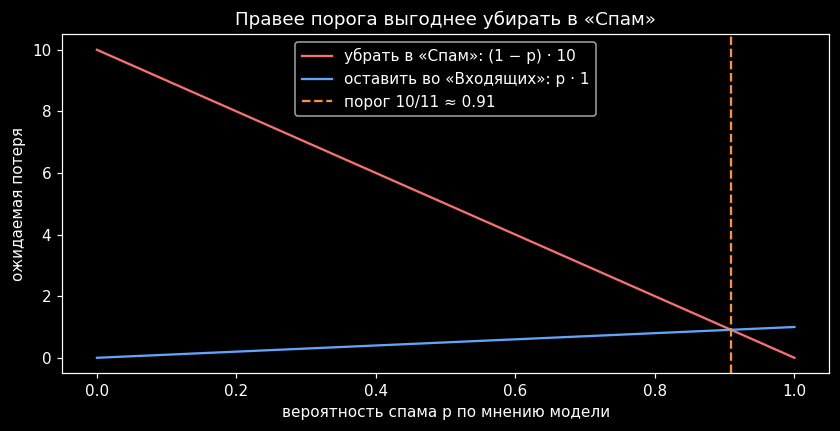

In [24]:
p = np.linspace(0, 1, 101)
plt.figure(figsize=(9, 4))
plt.plot(p, (1 - p) * 10, color="#f87171", label="убрать в «Спам»: (1 − p) · 10")
plt.plot(p, p * 1, color="#60a5fa", label="оставить во «Входящих»: p · 1")
plt.axvline(10 / 11, color="#fb923c", ls="--", label="порог 10/11 ≈ 0.91")
plt.xlabel("вероятность спама p по мнению модели"); plt.ylabel("ожидаемая потеря"); plt.legend()
plt.title("Правее порога выгоднее убирать в «Спам»"); plt.show()

**Для ML.** Модель выдаёт вероятность, решение принимается по порогу, а порог выбирают по цене ошибок: 0.5 для равных ошибок, выше — когда дорога ложная тревога, ниже — когда дорог пропуск. Как измерить, насколько хороша модель при разных порогах, — на занятии 8.

## Главное после урока

```python
(rolls == 6).mean()                             # частота события = доля True в маске
data.groupby("pclass")["survived"].mean()       # P(выжил | класс) по данным
values @ probs                                  # матожидание: значения × вероятности
proba = model.predict_proba(X_test)[:, 1]       # вероятность класса 1
pred = (proba >= threshold).astype(int)         # ответ по порогу
```

1. Вероятность — к чему подходит частота при большом числе экспериментов. Модели оценивают вероятности частотами по данным.
2. Условная вероятность $P(A \mid B)$ — доля A среди случаев, где случилось B. $P(A \mid B)$ и $P(B \mid A)$ — разные числа.
3. «Хотя бы один» — через «ни одного»: $1 - (1 - p)^n$. Складывать вероятности нельзя.
4. Матожидание — среднее на длинной дистанции, а не самый вероятный результат.
5. Классификатор выдаёт вероятность; ответ — по порогу; порог выбирают по цене ошибок.

### Термины занятия

| Термин | Простыми словами |
| --- | --- |
| Случайный эксперимент | действие, результат которого заранее не известен |
| Исход | один из возможных результатов эксперимента |
| Событие | то, что после эксперимента случилось или нет |
| Вероятность | число от 0 до 1: насколько событие ожидаемо; подходящие исходы / все исходы |
| Частота | доля экспериментов, где событие случилось; оценка вероятности по данным |
| Условная вероятность $P(A \mid B)$ | вероятность A, когда известно, что случилось B |
| Независимые события | одно не меняет шансов другого; $P(A \text{ и } B) = P(A) \cdot P(B)$ |
| Противоположное событие | «A не случилось», вероятность $1 - P(A)$ |
| Случайная величина | число, которое узнаём после эксперимента; правило «исход → число» |
| Распределение | значения случайной величины и их вероятности |
| Матожидание | среднее значение на длинной дистанции: $\sum x_i p_i$ |
| Вероятность класса (`predict_proba`) | насколько модель уверена, что объект из этого класса |
| Порог | граница: вероятность не меньше порога → ответ «да» |